# Midfielder feature engineering

This is the dedicated MID research branch of `fantasy_premier_league.ipynb`, which remains the shared root pipeline. All midfielder-specific hypotheses, diagnostics, feature families, and walk-forward comparisons belong here. Only features that survive the agreed validation process should later flow back into the root notebook.

The first experiment tests exact player/team head-to-head history with shrinkage. The second tests a more stable idea: how many attacking opportunities an opponent has recently conceded to midfielders in the relevant home/away role. Correlation is diagnostic only; decisions use tie-aware walk-forward top-K set overlap.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

VAASTAV_ROOT = "https://raw.githubusercontent.com/vaastav/Fantasy-Premier-League/master/data"
SEASONS = ["2023-24", "2024-25", "2025-26"]
EVALUATION_SEASON = "2025-26"
SEASON_ORDER = {season: index for index, season in enumerate(SEASONS)}
K = 10
PLAYER_PRIOR_MINUTES = 450
SAME_VENUE_PRIOR_MINUTES = 900
TEAM_PRIOR_MATCHES = 5

print("Feature-history seasons:", SEASONS)
print("Evaluation season:", EVALUATION_SEASON)

Feature-history seasons: ['2023-24', '2024-25', '2025-26']
Evaluation season: 2025-26


## Build leak-safe fixture rows

Each row below is a midfielder in one fixture. Stable FPL player codes connect seasons. Every historical statistic is shifted, so the current fixture never contributes to its own feature.

In [2]:
def load_season(season):
    gw_url = f"{VAASTAV_ROOT}/{season}/gws/merged_gw.csv"
    teams_url = f"{VAASTAV_ROOT}/{season}/teams.csv"
    players_url = f"{VAASTAV_ROOT}/{season}/players_raw.csv"

    frame = pd.read_csv(gw_url)
    teams = pd.read_csv(teams_url)[["id", "name"]].rename(
        columns={"id": "opponent_team", "name": "opponent_name"}
    )
    codes = pd.read_csv(players_url)[["id", "code"]].rename(
        columns={"id": "element"}
    )

    frame["season"] = season
    frame = frame.merge(teams, on="opponent_team", how="left")
    frame = frame.merge(codes, on="element", how="left")
    return frame


all_fixture_rows = pd.concat(
    [load_season(season) for season in SEASONS], ignore_index=True, sort=False
).copy()

numeric_columns = [
    "expected_goals", "expected_assists", "goals_scored", "assists",
    "minutes", "total_points", "GW", "fixture",
]
for column in numeric_columns:
    all_fixture_rows[column] = pd.to_numeric(
        all_fixture_rows[column], errors="coerce"
    )

all_fixture_rows["position"] = all_fixture_rows["position"].replace({"AM": "MID"})
all_fixture_rows["kickoff_time"] = pd.to_datetime(
    all_fixture_rows["kickoff_time"], errors="coerce", utc=True
)
all_fixture_rows["season_order"] = all_fixture_rows["season"].map(SEASON_ORDER)
all_fixture_rows["player_key"] = np.where(
    all_fixture_rows["code"].notna(),
    "code-" + all_fixture_rows["code"].astype("Int64").astype(str),
    all_fixture_rows["season"].astype(str)
    + "-"
    + all_fixture_rows["element"].astype(str),
)
all_fixture_rows = all_fixture_rows.sort_values(
    ["kickoff_time", "season_order", "GW", "fixture", "player_key"]
).reset_index(drop=True)
fixture_rows = all_fixture_rows.loc[all_fixture_rows["position"].eq("MID")].copy()

print("MID fixture rows:", fixture_rows.shape)
display(
    fixture_rows.groupby("season").agg(
        gameweeks=("GW", "nunique"),
        players=("player_key", "nunique"),
        fixtures=("fixture", "nunique"),
    )
)

MID fixture rows: (38729, 58)


,gameweeks,players,fixtures
season,,,
2023-24,38,374,380
2024-25,38,367,380
2025-26,38,379,380


## Feature families

The baseline uses player form plus general venue context. Two independent challenger ideas are tested:

1. Exact matchup history:
   - player versus opponent;
   - player versus opponent at the same home/away role;
   - team versus opponent at the same venue role.
2. Opponent MID defensive style:
   - recent venue-specific xG, xA, goals, assists, and attacking returners conceded to all opposing midfielders.

Raw H2H rates are not used directly. Player rates receive a five-match prior, same-venue player rates a ten-match prior, and team-pair rates a five-match prior. Opponent-style rates pool the previous five gameweeks in the opponent's relevant home/away role, so they have materially more evidence than exact opponent identity.

In [3]:
def add_shifted_player_history(frame):
    frame = frame.copy()
    value_map = {
        "minutes": "minutes",
        "expected_goals": "xg",
        "expected_assists": "xa",
        "goals_scored": "goals",
        "assists": "assists",
    }
    player_gw = frame.groupby(
        ["player_key", "season", "season_order", "GW"], as_index=False
    )[list(value_map)].sum(min_count=1)
    player_gw = player_gw.sort_values(
        ["player_key", "season_order", "GW"]
    ).reset_index(drop=True)
    gw_group = player_gw.groupby("player_key", sort=False)

    for source, short_name in value_map.items():
        player_gw[f"player_prior_{short_name}"] = (
            gw_group[source].cumsum() - player_gw[source].fillna(0)
        )
        player_gw[f"recent_5_{short_name}"] = gw_group[source].transform(
            lambda values: values.shift().rolling(5, min_periods=1).sum()
        )

    history_columns = [
        column for column in player_gw.columns
        if column.startswith("player_prior_") or column.startswith("recent_5_")
    ]
    frame = frame.merge(
        player_gw[["player_key", "season", "GW"] + history_columns],
        on=["player_key", "season", "GW"],
        how="left",
    )
    prior_minutes = frame["player_prior_minutes"].replace(0, np.nan)
    recent_minutes = frame["recent_5_minutes"].replace(0, np.nan)
    frame["player_xg_per90"] = 90 * frame["player_prior_xg"] / prior_minutes
    frame["player_xa_per90"] = 90 * frame["player_prior_xa"] / prior_minutes
    frame["recent_5_xg_per90"] = 90 * frame["recent_5_xg"] / recent_minutes
    frame["recent_5_xa_per90"] = 90 * frame["recent_5_xa"] / recent_minutes

    h2h_group = frame.groupby(["player_key", "opponent_name"], sort=False)
    venue_group = frame.groupby(
        ["player_key", "opponent_name", "was_home"], sort=False
    )
    for source, short_name in [
        ("minutes", "minutes"),
        ("expected_goals", "xg"),
        ("expected_assists", "xa"),
        ("goals_scored", "goals"),
        ("assists", "assists"),
    ]:
        frame[f"h2h_prior_{short_name}"] = (
            h2h_group[source].cumsum() - frame[source].fillna(0)
        )
        frame[f"h2h_venue_prior_{short_name}"] = (
            venue_group[source].cumsum() - frame[source].fillna(0)
        )

    frame["appeared"] = frame["minutes"].fillna(0).gt(0).astype(int)
    frame["h2h_prior_matches"] = (
        h2h_group["appeared"].cumsum() - frame["appeared"]
    )
    frame["h2h_venue_prior_matches"] = (
        venue_group["appeared"].cumsum() - frame["appeared"]
    )

    for metric in ["xg", "xa"]:
        general_rate = frame[f"player_{metric}_per90"] / 90
        frame[f"h2h_{metric}_per90_shrunk"] = 90 * (
            frame[f"h2h_prior_{metric}"] + PLAYER_PRIOR_MINUTES * general_rate
        ) / (frame["h2h_prior_minutes"] + PLAYER_PRIOR_MINUTES)
        frame[f"h2h_venue_{metric}_per90_shrunk"] = 90 * (
            frame[f"h2h_venue_prior_{metric}"]
            + SAME_VENUE_PRIOR_MINUTES * general_rate
        ) / (frame["h2h_venue_prior_minutes"] + SAME_VENUE_PRIOR_MINUTES)
        frame[f"h2h_{metric}_delta"] = (
            frame[f"h2h_{metric}_per90_shrunk"] - frame[f"player_{metric}_per90"]
        )
        frame[f"h2h_venue_{metric}_delta"] = (
            frame[f"h2h_venue_{metric}_per90_shrunk"] - frame[f"player_{metric}_per90"]
        )
    return frame


def build_team_fixture_history(frame):
    team_xg = (
        frame.groupby(
            ["season", "GW", "fixture", "team", "opponent_name", "was_home"],
            as_index=False,
        )["expected_goals"]
        .sum(min_count=1)
        .rename(columns={"expected_goals": "team_xg"})
    )
    opponent_xg = team_xg[
        ["season", "GW", "fixture", "team", "team_xg"]
    ].rename(columns={"team": "opponent_name", "team_xg": "team_xga"})
    team_fixtures = team_xg.merge(
        opponent_xg,
        on=["season", "GW", "fixture", "opponent_name"],
        how="left",
    )
    team_fixtures["season_order"] = team_fixtures["season"].map(SEASON_ORDER)
    team_fixtures = team_fixtures.sort_values(
        ["season_order", "GW", "fixture", "team"]
    ).reset_index(drop=True)

    venue_gw = team_fixtures.groupby(
        ["team", "was_home", "season", "season_order", "GW"], as_index=False
    ).agg(
        team_xg=("team_xg", "sum"),
        team_xga=("team_xga", "sum"),
        venue_matches=("fixture", "nunique"),
    )
    venue_gw = venue_gw.sort_values(
        ["team", "was_home", "season_order", "GW"]
    ).reset_index(drop=True)
    venue_group = venue_gw.groupby(["team", "was_home"], sort=False)
    venue_gw["team_venue_prior_matches"] = (
        venue_group["venue_matches"].cumsum() - venue_gw["venue_matches"]
    )
    for metric in ["team_xg", "team_xga"]:
        venue_gw[f"{metric}_venue_prior_sum"] = (
            venue_group[metric].cumsum() - venue_gw[metric].fillna(0)
        )
        venue_gw[f"{metric}_venue_rate"] = (
            venue_gw[f"{metric}_venue_prior_sum"]
            / venue_gw["team_venue_prior_matches"].replace(0, np.nan)
        )

    venue_columns = [
        "team", "was_home", "season", "GW", "team_venue_prior_matches",
        "team_xg_venue_rate", "team_xga_venue_rate",
    ]
    team_fixtures = team_fixtures.merge(
        venue_gw[venue_columns],
        on=["team", "was_home", "season", "GW"],
        how="left",
    )
    pair_group = team_fixtures.groupby(
        ["team", "opponent_name", "was_home"], sort=False
    )
    team_fixtures["team_pair_prior_matches"] = pair_group.cumcount()
    team_fixtures["team_pair_xg_prior_sum"] = (
        pair_group["team_xg"].cumsum() - team_fixtures["team_xg"].fillna(0)
    )
    team_fixtures["team_pair_xg_rate_shrunk"] = (
        team_fixtures["team_pair_xg_prior_sum"]
        + TEAM_PRIOR_MATCHES * team_fixtures["team_xg_venue_rate"]
    ) / (team_fixtures["team_pair_prior_matches"] + TEAM_PRIOR_MATCHES)

    opponent_context = team_fixtures[
        ["season", "GW", "fixture", "team", "team_xga_venue_rate"]
    ].rename(
        columns={
            "team": "opponent_name",
            "team_xga_venue_rate": "opponent_venue_xga_rate",
        }
    )
    team_fixtures = team_fixtures.merge(
        opponent_context,
        on=["season", "GW", "fixture", "opponent_name"],
        how="left",
    )
    return team_fixtures


def build_opponent_mid_style(frame):
    """Recent MID opportunities conceded by each defence in the same venue role."""
    frame = frame.copy()
    mid_rows = frame.loc[frame["position"].eq("MID")].copy()
    mid_rows["mid_returner"] = (
        mid_rows["goals_scored"].fillna(0) + mid_rows["assists"].fillna(0)
    ).gt(0).astype(int)
    attacking_mid = mid_rows.groupby(
        ["season", "GW", "fixture", "team"], as_index=False
    ).agg(
        mid_xg=("expected_goals", "sum"),
        mid_xa=("expected_assists", "sum"),
        mid_goals=("goals_scored", "sum"),
        mid_assists=("assists", "sum"),
        mid_returners=("mid_returner", "sum"),
    )
    attacking_mid = attacking_mid.rename(columns={"team": "opponent_name"})

    defending_team = frame[
        ["season", "GW", "fixture", "team", "opponent_name", "was_home"]
    ].drop_duplicates(["season", "fixture", "team"])
    defending_team = defending_team.merge(
        attacking_mid,
        on=["season", "GW", "fixture", "opponent_name"],
        how="left",
    )
    defending_team["season_order"] = defending_team["season"].map(SEASON_ORDER)

    metric_columns = [
        "mid_xg", "mid_xa", "mid_goals", "mid_assists", "mid_returners"
    ]
    venue_gw = defending_team.groupby(
        ["team", "was_home", "season", "season_order", "GW"], as_index=False
    ).agg(
        **{metric: (metric, "sum") for metric in metric_columns},
        venue_matches=("fixture", "nunique"),
    )
    venue_gw = venue_gw.sort_values(
        ["team", "was_home", "season_order", "GW"]
    ).reset_index(drop=True)
    venue_group = venue_gw.groupby(["team", "was_home"], sort=False)
    venue_gw["recent_5_prior_matches"] = venue_group["venue_matches"].transform(
        lambda values: values.shift().rolling(5, min_periods=1).sum()
    )
    style_columns = []
    for metric in metric_columns:
        prior_sum = venue_group[metric].transform(
            lambda values: values.shift().rolling(5, min_periods=1).sum()
        )
        column = f"opponent_{metric}_conceded_venue_recent5"
        venue_gw[column] = prior_sum / venue_gw["recent_5_prior_matches"].replace(
            0, np.nan
        )
        style_columns.append(column)

    defending_team = defending_team.merge(
        venue_gw[
            ["team", "was_home", "season", "GW", "recent_5_prior_matches"]
            + style_columns
        ],
        on=["team", "was_home", "season", "GW"],
        how="left",
    )
    opponent_style = defending_team[
        ["season", "GW", "fixture", "team", "recent_5_prior_matches"]
        + style_columns
    ].rename(
        columns={
            "team": "opponent_name",
            "recent_5_prior_matches": "opponent_style_prior_matches",
        }
    )
    return opponent_style, style_columns


fixture_features = add_shifted_player_history(fixture_rows)
team_history = build_team_fixture_history(all_fixture_rows)
team_feature_columns = [
    "season", "GW", "fixture", "team", "team_venue_prior_matches",
    "team_pair_prior_matches", "team_xg_venue_rate", "team_xga_venue_rate",
    "opponent_venue_xga_rate", "team_pair_xg_rate_shrunk",
]
fixture_features = fixture_features.merge(
    team_history[team_feature_columns],
    on=["season", "GW", "fixture", "team"],
    how="left",
)
opponent_style, opponent_style_features = build_opponent_mid_style(all_fixture_rows)
fixture_features = fixture_features.merge(
    opponent_style,
    on=["season", "GW", "fixture", "opponent_name"],
    how="left",
)
opponent_style_features = ["opponent_style_prior_matches"] + opponent_style_features

print("Feature rows:", fixture_features.shape)
print("Opponent MID style features:", opponent_style_features)
display(
    fixture_features[
        [
            "season", "GW", "name", "team", "opponent_name", "was_home",
            "h2h_prior_matches", "h2h_venue_prior_matches",
            "h2h_xg_per90_shrunk", "h2h_xa_per90_shrunk",
            "team_pair_prior_matches", "team_pair_xg_rate_shrunk",
            "opponent_mid_xg_conceded_venue_recent5",
            "opponent_mid_xa_conceded_venue_recent5",
        ]
    ].tail(10)
)

Feature rows: (38729, 105)
Opponent MID style features: ['opponent_style_prior_matches', 'opponent_mid_xg_conceded_venue_recent5', 'opponent_mid_xa_conceded_venue_recent5', 'opponent_mid_goals_conceded_venue_recent5', 'opponent_mid_assists_conceded_venue_recent5', 'opponent_mid_returners_conceded_venue_recent5']


,season,GW,name,team,opponent_name,was_home,h2h_prior_matches,h2h_venue_prior_matches,h2h_xg_per90_shrunk,h2h_xa_per90_shrunk,team_pair_prior_matches,team_pair_xg_rate_shrunk,opponent_mid_xg_conceded_venue_recent5,opponent_mid_xa_conceded_venue_recent5
38719,2025-26,38,Charlie Crew,Leeds,West Ham,False,0,0,NaN,NaN,0,1.263889,0.54,0.908
38720,2025-26,38,Facundo Buonanotte,Leeds,West Ham,False,3,2,0.130634,0.103015,0,1.263889,0.54,0.908
38721,2025-26,38,Mateus Gonçalo Espanha Fernandes,West Ham,Leeds,True,1,0,0.106142,0.097407,0,1.303929,0.63,0.568
38722,2025-26,38,Soungoutou Magassa,West Ham,Leeds,True,1,0,0.039810,0.028952,0,1.303929,0.63,0.568
38723,2025-26,38,Sam Chambers,Leeds,West Ham,False,0,0,NaN,NaN,0,1.263889,0.54,0.908
38724,2025-26,38,Keiber Lamadrid,West Ham,Leeds,True,0,0,NaN,NaN,0,1.303929,0.63,0.568
38725,2025-26,38,Luis Guilherme Lira dos Santos,West Ham,Leeds,True,0,0,0.169615,0.055385,0,1.303929,0.63,0.568
38726,2025-26,38,Rhys Chadwick,Leeds,West Ham,False,0,0,NaN,NaN,0,1.263889,0.54,0.908
38727,2025-26,38,Alfie Cresswell,Leeds,West Ham,False,0,0,NaN,NaN,0,1.263889,0.54,0.908
38728,2025-26,38,Mohamadou Kanté,West Ham,Leeds,True,0,0,0.096923,0.055385,0,1.303929,0.63,0.568


## Collapse to player-gameweek and define the target

Double gameweeks are collapsed before labeling. Feature values are averaged across that gameweek's fixtures, while points and minutes are summed. The target is tie-aware membership of the actual MID top K; ordering inside the selected set is irrelevant. The accepted configuration uses `K = 10`; the rejected top-7 experiment produced a weaker later-block result.

In [4]:
baseline_features = [
    "was_home", "player_prior_minutes", "recent_5_minutes",
    "player_xg_per90", "player_xa_per90",
    "recent_5_xg_per90", "recent_5_xa_per90",
    "team_xg_venue_rate", "opponent_venue_xga_rate",
]
player_h2h_features = [
    "h2h_prior_matches", "h2h_venue_prior_matches",
    "h2h_xg_per90_shrunk", "h2h_xa_per90_shrunk",
    "h2h_venue_xg_per90_shrunk", "h2h_venue_xa_per90_shrunk",
    "h2h_xg_delta", "h2h_xa_delta",
    "h2h_venue_xg_delta", "h2h_venue_xa_delta",
]
team_h2h_features = [
    "team_pair_prior_matches", "team_pair_xg_rate_shrunk",
]
all_feature_columns = (
    baseline_features
    + player_h2h_features
    + team_h2h_features
    + opponent_style_features
)

aggregation = {
    "name": "first",
    "team": "first",
    "opponent_name": lambda values: " / ".join(sorted(values.dropna().unique())),
    "total_points": "sum",
    "minutes": "sum",
    "fixture": "nunique",
}
aggregation.update({column: "mean" for column in all_feature_columns})
player_gw = fixture_features.groupby(
    ["season", "season_order", "GW", "player_key"], as_index=False
).agg(aggregation)
player_gw = player_gw.rename(columns={"fixture": "fixture_count"})
player_gw["top_k_mid"] = 0

for (_, _), indices in player_gw.groupby(["season", "GW"]).groups.items():
    week_points = player_gw.loc[indices, "total_points"]
    cutoff = week_points.nlargest(min(K, len(week_points))).min()
    player_gw.loc[indices, "top_k_mid"] = week_points.ge(cutoff).astype(int)

player_gw["eligible"] = player_gw["recent_5_minutes"].fillna(0).gt(0)
print("Player-gameweek rows:", player_gw.shape)
print("Eligible share:", player_gw["eligible"].mean().round(3))
display(
    player_gw.loc[player_gw["season"].eq(EVALUATION_SEASON)]
    .groupby("GW")["top_k_mid"]
    .sum()
    .describe()
)

Player-gameweek rows: (37936, 39)
Eligible share: 0.561


count    38.000000
mean     11.736842
std       2.022632
min      10.000000
25%      10.000000
50%      11.000000
75%      13.000000
max      18.000000
Name: top_k_mid, dtype: float64

## Development-only coverage and correlation

Feature inspection is restricted to 2025-26 GW1-19. This answers three questions: how often exact history exists, whether the broader opponent-style profile fixes that sparsity, and whether the leak-safe values relate to future points or top-K membership. A low raw correlation does not automatically remove a feature; the walk-forward comparison remains decisive.

minimum_prior_matches,1,2,3
history,,,
"Opponent MID style, same venue",0.990657,0.979940,0.968398
Player vs opponent,0.633416,0.505359,0.319868
"Player vs opponent, same venue",0.536961,0.242649,0.001924
"Team vs opponent, same venue",0.816983,0.728222,0.000000


,feature,non_missing_share,pearson_with_points,spearman_with_points,correlation_with_top_k
11,team_pair_xg_rate_shrunk,0.994779,0.063536,0.032310,0.072744
0,h2h_prior_matches,1.000000,0.080966,0.096372,0.047164
3,h2h_xa_per90_shrunk,1.000000,0.048452,0.074759,0.044914
5,h2h_venue_xa_per90_shrunk,1.000000,0.049480,0.079354,0.044008
16,opponent_mid_assists_conceded_venue_recent5,0.990657,0.034427,0.012087,0.043504
1,h2h_venue_prior_matches,1.000000,0.068196,0.090596,0.042232
13,opponent_mid_xg_conceded_venue_recent5,0.990657,0.044108,0.019290,0.039896
14,opponent_mid_xa_conceded_venue_recent5,0.990657,0.041509,0.028645,0.037436
17,opponent_mid_returners_conceded_venue_recent5,0.990657,0.028800,0.004957,0.033391
15,opponent_mid_goals_conceded_venue_recent5,0.990657,0.025735,0.005831,0.019531


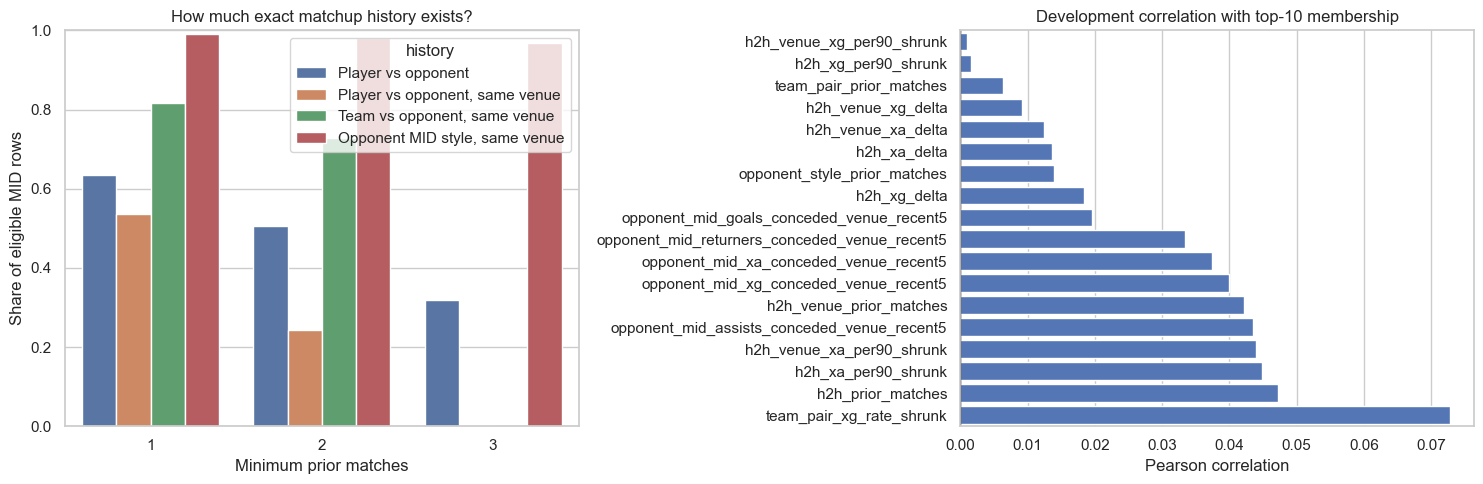

In [5]:
development = player_gw.loc[
    player_gw["season"].eq(EVALUATION_SEASON)
    & player_gw["GW"].between(1, 19)
    & player_gw["eligible"]
].copy()

coverage_rows = []
for label, column in [
    ("Player vs opponent", "h2h_prior_matches"),
    ("Player vs opponent, same venue", "h2h_venue_prior_matches"),
    ("Team vs opponent, same venue", "team_pair_prior_matches"),
    ("Opponent MID style, same venue", "opponent_style_prior_matches"),
]:
    for threshold in [1, 2, 3]:
        coverage_rows.append(
            {
                "history": label,
                "minimum_prior_matches": threshold,
                "coverage": development[column].ge(threshold).mean(),
            }
        )
coverage = pd.DataFrame(coverage_rows)

diagnostic_features = (
    player_h2h_features + team_h2h_features + opponent_style_features
)
correlation_rows = []
for feature in diagnostic_features:
    valid = development[[feature, "total_points", "top_k_mid"]].dropna()
    correlation_rows.append(
        {
            "feature": feature,
            "non_missing_share": len(valid) / len(development),
            "pearson_with_points": valid[feature].corr(valid["total_points"]),
            "spearman_with_points": valid[feature].corr(
                valid["total_points"], method="spearman"
            ),
            "correlation_with_top_k": valid[feature].corr(valid["top_k_mid"]),
        }
    )
correlations = pd.DataFrame(correlation_rows).sort_values(
    "correlation_with_top_k", key=lambda values: values.abs(), ascending=False
)

display(coverage.pivot(index="history", columns="minimum_prior_matches", values="coverage"))
display(correlations)

figure, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(
    data=coverage,
    x="minimum_prior_matches",
    y="coverage",
    hue="history",
    ax=axes[0],
)
axes[0].set_title("How much exact matchup history exists?")
axes[0].set_xlabel("Minimum prior matches")
axes[0].set_ylabel("Share of eligible MID rows")
axes[0].set_ylim(0, 1)

plot_correlations = correlations.sort_values("correlation_with_top_k")
sns.barplot(
    data=plot_correlations,
    x="correlation_with_top_k",
    y="feature",
    color="#4472C4",
    ax=axes[1],
)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title(f"Development correlation with top-{K} membership")
axes[1].set_xlabel("Pearson correlation")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

## Walk-forward feature-family comparison

Four logistic models differ only by feature family: baseline, player H2H, player plus team H2H, and opponent MID defensive style. For every evaluated gameweek, training uses earlier rows only, and each historical gameweek receives equal total weight. Model selection uses GW1-19; GW20-38 is displayed once as a historical check.

Selected on GW1-19: baseline_plus_opponent_mid_style


block,development_gw1_19,historical_check_gw20_38
feature_family,,
baseline,0.168421,0.173684
baseline_plus_opponent_mid_style,0.178947,0.184211
baseline_plus_player_and_team_h2h,0.173684,0.142105
baseline_plus_player_h2h,0.178947,0.147368


,feature_family,block,mean_hit_rate,correct_predictions,predictions
0,baseline,development_gw1_19,0.168421,32,190
1,baseline,historical_check_gw20_38,0.173684,33,190
2,baseline_plus_opponent_mid_style,development_gw1_19,0.178947,34,190
3,baseline_plus_opponent_mid_style,historical_check_gw20_38,0.184211,35,190
4,baseline_plus_player_h2h,development_gw1_19,0.178947,34,190
5,baseline_plus_player_h2h,historical_check_gw20_38,0.147368,28,190
6,baseline_plus_player_and_team_h2h,development_gw1_19,0.173684,33,190
7,baseline_plus_player_and_team_h2h,historical_check_gw20_38,0.142105,27,190


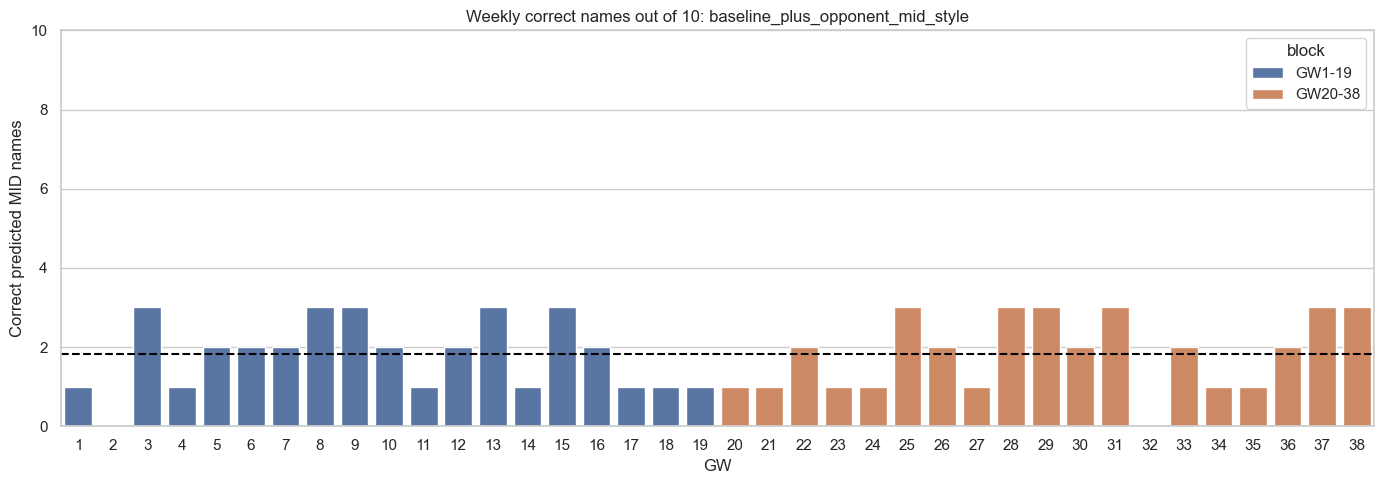

In [6]:
feature_families = {
    "baseline": baseline_features,
    "baseline_plus_opponent_mid_style": baseline_features + opponent_style_features,
    "baseline_plus_player_h2h": baseline_features + player_h2h_features,
    "baseline_plus_player_and_team_h2h": (
        baseline_features + player_h2h_features + team_h2h_features
    ),
}


def make_model():
    return Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            (
                "model",
                LogisticRegression(
                    max_iter=2000,
                    class_weight="balanced",
                    random_state=42,
                ),
            ),
        ]
    )


def run_walk_forward(frame, feature_columns, start_gw, end_gw):
    rows = []
    evaluation_order = SEASON_ORDER[EVALUATION_SEASON]
    for gw in range(start_gw, end_gw + 1):
        train_mask = frame["eligible"] & (
            frame["season_order"].lt(evaluation_order)
            | (
                frame["season"].eq(EVALUATION_SEASON)
                & frame["GW"].lt(gw)
            )
        )
        test_mask = (
            frame["eligible"]
            & frame["season"].eq(EVALUATION_SEASON)
            & frame["GW"].eq(gw)
        )
        train = frame.loc[train_mask].copy()
        test = frame.loc[test_mask].copy()
        if train.empty or test.empty or train["top_k_mid"].nunique() < 2:
            continue

        week_size = train.groupby(["season", "GW"])["player_key"].transform("size")
        sample_weight = 1 / week_size
        model = make_model()
        model.fit(
            train[feature_columns],
            train["top_k_mid"],
            model__sample_weight=sample_weight,
        )
        test["score"] = model.predict_proba(test[feature_columns])[:, 1]
        predicted = test.nlargest(min(K, len(test)), "score").copy()
        actual = frame.loc[
            frame["season"].eq(EVALUATION_SEASON)
            & frame["GW"].eq(gw)
            & frame["top_k_mid"].eq(1)
        ].copy()
        correct_names = sorted(set(predicted["name"]) & set(actual["name"]))
        rows.append(
            {
                "GW": gw,
                "correct": len(correct_names),
                "hit_rate": len(correct_names) / len(predicted),
                "actual_top_group_size": len(actual),
                "predicted_names": predicted["name"].tolist(),
                "correct_names": correct_names,
            }
        )
    return pd.DataFrame(rows)


backtests = {}
summary_rows = []
for family, features in feature_families.items():
    development_result = run_walk_forward(player_gw, features, 1, 19)
    check_result = run_walk_forward(player_gw, features, 20, 38)
    backtests[(family, "development")] = development_result
    backtests[(family, "historical_check")] = check_result
    summary_rows.extend(
        [
            {
                "feature_family": family,
                "block": "development_gw1_19",
                "mean_hit_rate": development_result["hit_rate"].mean(),
                "correct_predictions": development_result["correct"].sum(),
                "predictions": K * len(development_result),
            },
            {
                "feature_family": family,
                "block": "historical_check_gw20_38",
                "mean_hit_rate": check_result["hit_rate"].mean(),
                "correct_predictions": check_result["correct"].sum(),
                "predictions": K * len(check_result),
            },
        ]
    )

comparison = pd.DataFrame(summary_rows)
development_comparison = comparison.loc[
    comparison["block"].eq("development_gw1_19")
].sort_values("mean_hit_rate", ascending=False)
selected_family = development_comparison.iloc[0]["feature_family"]

print("Selected on GW1-19:", selected_family)
display(comparison.pivot(index="feature_family", columns="block", values="mean_hit_rate"))
display(comparison)

selected_weekly = pd.concat(
    [
        backtests[(selected_family, "development")].assign(block="GW1-19"),
        backtests[(selected_family, "historical_check")].assign(block="GW20-38"),
    ],
    ignore_index=True,
)
plt.figure(figsize=(14, 5))
sns.barplot(data=selected_weekly, x="GW", y="correct", hue="block", dodge=False)
plt.axhline(selected_weekly["correct"].mean(), color="black", linestyle="--")
plt.title(f"Weekly correct names out of {K}: {selected_family}")
plt.ylabel("Correct predicted MID names")
plt.ylim(0, K)
plt.tight_layout()
plt.show()

## Decision

These experiments are allowed to reject their hypotheses. A development improvement is insufficient if it reverses on the later block. This focused MID notebook is not automatically a replacement for the stronger route model in the root notebook; each feature family must add stable information and then survive prospective confirmation before integration.

In [7]:
result_pivot = comparison.pivot(
    index="feature_family", columns="block", values="mean_hit_rate"
)
baseline_development = result_pivot.loc["baseline", "development_gw1_19"]
baseline_check = result_pivot.loc["baseline", "historical_check_gw20_38"]
selected_development = result_pivot.loc[selected_family, "development_gw1_19"]
selected_check = result_pivot.loc[selected_family, "historical_check_gw20_38"]

same_venue_three_match_coverage = coverage.loc[
    coverage["history"].eq("Player vs opponent, same venue")
    & coverage["minimum_prior_matches"].eq(3),
    "coverage",
].iloc[0]
style_three_match_coverage = coverage.loc[
    coverage["history"].eq("Opponent MID style, same venue")
    & coverage["minimum_prior_matches"].eq(3),
    "coverage",
].iloc[0]

print(f"Selected family: {selected_family}")
print(
    "Development uplift over baseline: "
    f"{selected_development - baseline_development:+.3f}"
)
print(
    "Historical-check uplift over baseline: "
    f"{selected_check - baseline_check:+.3f}"
)
print(
    "Same-venue player H2H coverage with at least three prior appearances: "
    f"{same_venue_three_match_coverage:.1%}"
)
print(
    "Opponent-style coverage with at least three prior venue matches: "
    f"{style_three_match_coverage:.1%}"
)

if selected_family == "baseline":
    print("Decision: none of the added MID feature families beat the baseline.")
elif selected_check > baseline_check:
    print(
        f"Decision: keep {selected_family} shadow-only and require prospective "
        "confirmation before changing the root model."
    )
else:
    print(
        f"Decision: reject {selected_family} as a root-model addition because "
        "its development gain reversed on the later block."
    )

Selected family: baseline_plus_opponent_mid_style
Development uplift over baseline: +0.011
Historical-check uplift over baseline: +0.011
Same-venue player H2H coverage with at least three prior appearances: 0.2%
Opponent-style coverage with at least three prior venue matches: 96.8%
Decision: keep baseline_plus_opponent_mid_style shadow-only and require prospective confirmation before changing the root model.
